# CSV-filer og tidskodar

I denne notatboka lærer du:

- kva ei CSV-fil er, og korleis ho ser ut på innsida
- korleis vi skriv **tidspunkt** slik at datamaskina (og andre menneske) skjønar dei
- å **skrive** og **lese** CSV-filer med Python
- å lese CSV-filer med **Pandas**

Køyr cellene ei etter ei med `Shift + Enter`.

## 1. Kva er ei CSV-fil?

CSV står for *Comma-Separated Values*, altså «verdiar skilde med komma». Det er ei vanleg tekstfil der:

- kvar **linje** er ei rad (til dømes éi måling)
- **komma** skil kolonnane frå kvarandre
- den **første linja** (overskrifta) seier kva kolonnane heiter

Slik ser starten av fila med badetemperaturar frå Nordnes Sjøbad i Bergen ut:

```text
tid,temperatur,lufttemperatur
2024-05-21 13:29:27,15.6,NaN
2024-05-21 21:49:32,17.6,NaN
```

Fordi CSV berre er tekst, kan du opne fila i VS Code, Notisblokk, Excel og nesten alle andre program. Det er derfor CSV er så populært for måledata.

> **Prøv sjølv:** Opne `data/nordnes-sjobad.csv` i VS Code (dobbeltklikk på fila i utforskaren til venstre). Kor mange linjer har fila?

Vi kan òg lese dei første linjene med vanleg Python:

In [1]:
with open("data/nordnes-sjobad.csv", encoding="utf-8") as fil:
    for i in range(6):
        linje = fil.readline()
        print(linje, end="")

tid,temperatur,lufttemperatur
2024-05-21 13:29:27,15.6,NaN
2024-05-21 21:49:32,17.6,NaN
2024-05-21 21:59:44,17.3,NaN
2024-05-21 22:30:47,17.3,NaN
2024-05-21 22:41:43,17.5,NaN


### Desimalkomma eller desimalpunktum?

I Noreg skriv vi `15,6`, men i CSV-filer (og i Python) brukar vi nesten alltid **punktum**: `15.6`. Elles ville ikkje datamaskina vite om kommaet er eit desimalteikn eller skiljer to kolonnar.

Lagrar du ei CSV-fil frå norsk Excel, brukar Excel ofte **semikolon** som skiljeteikn og **komma** som desimalteikn:

```text
tid;temperatur
2024-05-21 13:29:27;15,6
```

Det går fint å lese slike filer med Pandas òg. Du må berre seie frå: `pd.read_csv("fil.csv", sep=";", decimal=",")`.

## 2. Tidskodar

Når vi måler noko over tid, må vi lagre **når** kvar måling vart gjort. Det finst mange måtar å skrive dato på:

| Skrivemåte | Problem |
|---|---|
| `4/11/26` | Er det 4. november eller 11. april (amerikansk)? Kva hundreår? |
| `4. nov. 2026 kl. 21` | Vanskeleg for datamaskina å lese. Avheng av språk. |
| `2026-11-04 21:00:00` | **Eintydig.** Dette er den internasjonale standarden **ISO 8601**. |

ISO 8601 går frå det **største** til det **minste**: år, månad, dag, time, minutt, sekund. Det har ein ekstra fordel: når du sorterer tidspunkta som vanleg tekst, kjem dei i rett tidsrekkjefølgje.

I Python hentar vi tida med modulen `datetime`:

In [2]:
from datetime import datetime

no = datetime.now()
print(no)
print(no.strftime("%Y-%m-%d %H:%M:%S"))   # ISO 8601 utan mikrosekund

2026-11-04 21:44:34.983772
2026-11-04 21:44:34


`strftime` står for *string format time*. Bokstavane etter `%` seier kva som skal skrivast:

| Kode | Tyding | Døme |
|---|---|---|
| `%Y` | år (fire siffer) | 2026 |
| `%m` | månad (to siffer) | 11 |
| `%d` | dag | 04 |
| `%H` | time (00–23) | 21 |
| `%M` | minutt | 05 |
| `%S` | sekund | 09 |

### Tidssoner og sommartid

Klokka i Noreg blir stilt éin time fram om våren og éin time tilbake om hausten. Det gjer at det same klokkeslettet kan finnast **to gonger** om hausten, og eitt klokkeslett **manglar** om våren. Sjå kva som skjedde i datafila natt til 26. oktober 2025:

In [3]:
with open("data/nordnes-sjobad.csv", encoding="utf-8") as fil:
    for linje in fil:
        if linje.startswith("2025-10-26 0"):
            print(linje, end="")

2025-10-26 00:00:07,11.4,10.1
2025-10-26 01:00:03,11.5,9.5
2025-10-26 02:00:04,11.6,9.5
2025-10-26 02:00:04,11.5,9.7
2025-10-26 03:00:05,11.6,9.7
2025-10-26 04:00:03,11.6,9.7
2025-10-26 05:00:03,11.8,9.5
2025-10-26 06:00:03,11.0,9.5
2025-10-26 07:00:02,11.2,9.8
2025-10-26 08:00:03,11.4,9.7
2025-10-26 09:00:03,11.3,9.8


Klokka 02:00 finst to gonger! Profesjonelle målestasjonar lagrar derfor ofte tida i **UTC** (verdstid), som ikkje har sommartid. Til skuleprosjekt går det greitt å bruke norsk tid, så lenge du veit om dette.

## 3. Skrive ei CSV-fil med Python

No lagar vi ei CSV-fil sjølv. Vi har ikkje sensoren kopla til enno, så vi lagar **simulerte** målingar: 10 målingar med eitt minutts mellomrom, med litt tilfeldig variasjon rundt 21 °C.

Modulen `csv` tek seg av komma, linjeskift og liknande for oss.

In [4]:
import csv
import random
from datetime import datetime, timedelta

starttid = datetime(2026, 11, 10, 9, 0, 0)    # 10. november 2026 kl. 09:00:00

with open("mine-maalingar.csv", "w", newline="", encoding="utf-8") as fil:
    skrivar = csv.writer(fil)
    skrivar.writerow(["tid", "temperatur"])           # overskrift

    for i in range(10):
        tid = starttid + timedelta(minutes=i)
        temperatur = round(21 + random.uniform(-0.5, 0.5), 2)
        skrivar.writerow([tid.strftime("%Y-%m-%d %H:%M:%S"), temperatur])

print("Ferdig! Opne mine-maalingar.csv i VS Code og sjå på innhaldet.")

Ferdig! Opne mine-maalingar.csv i VS Code og sjå på innhaldet.


Nokre detaljar:

- `"w"` betyr *write*. Fila blir laga på nytt (og det gamle innhaldet sletta). Brukar du `"a"` (*append*), blir nye linjer lagt til på slutten.
- `newline=""` hindrar tomme linjer mellom radene på Windows.
- `encoding="utf-8"` gjer at æ, ø og å blir lagra rett.

## 4. Lese ei CSV-fil med `csv`-modulen

In [5]:
tider = []
temperaturar = []

with open("mine-maalingar.csv", encoding="utf-8") as fil:
    lesar = csv.reader(fil)
    overskrift = next(lesar)          # hopp over første linje
    for rad in lesar:
        tider.append(rad[0])
        temperaturar.append(float(rad[1]))   # tekst -> desimaltal

print("Kolonnar:", overskrift)
print("Tal på målingar:", len(temperaturar))
print("Gjennomsnitt:", sum(temperaturar) / len(temperaturar))
print("Høgaste:", max(temperaturar))

Kolonnar: ['tid', 'temperatur']
Tal på målingar: 10
Gjennomsnitt: 20.964
Høgaste: 21.22


Legg merke til `float(rad[1])`. Alt som blir lese frå ei tekstfil er **tekst** (`str`) til vi gjer det om til tal.

Dette fungerer, men blir fort tungvint når vi har mange kolonnar og tusenvis av rader. Derfor brukar vi biblioteket **Pandas**.

## 5. Lese ei CSV-fil med Pandas

Pandas les heile fila inn i ein **DataFrame**, som er ein tabell med rader og kolonnar. Vi gir to ekstra beskjedar:

- `parse_dates=["tid"]`: kolonnen `tid` inneheld tidspunkt, ikkje vanleg tekst
- `index_col="tid"`: bruk tida som *indeks* (radnamn). Då blir det lett å plukke ut periodar og teikne grafar over tid.

In [6]:
import pandas as pd

data = pd.read_csv("mine-maalingar.csv", parse_dates=["tid"], index_col="tid")
data

,temperatur
tid,
2026-11-10 09:00:00,21.22
2026-11-10 09:01:00,20.72
2026-11-10 09:02:00,20.95
2026-11-10 09:03:00,20.72
2026-11-10 09:04:00,21.15
2026-11-10 09:05:00,21.15
2026-11-10 09:06:00,20.74
2026-11-10 09:07:00,21.12
2026-11-10 09:08:00,20.77


In [7]:
print("Gjennomsnitt:", data["temperatur"].mean())
print("Høgaste:", data["temperatur"].max())

Gjennomsnitt: 20.964
Høgaste: 21.22


Og ein graf, med éi linje kode:

Matplotlib is building the font cache; this may take a moment.


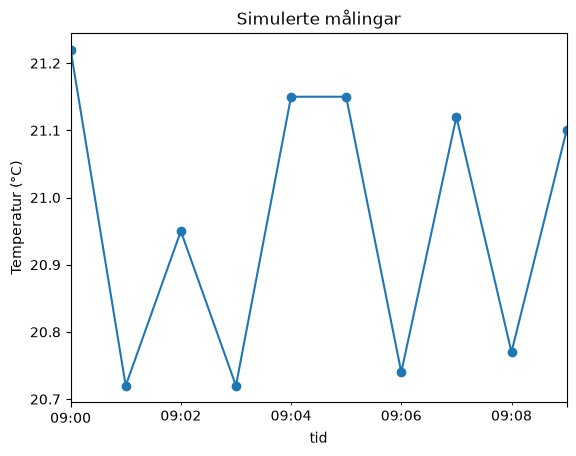

In [8]:
data["temperatur"].plot(title="Simulerte målingar", ylabel="Temperatur (°C)", marker="o");

## Oppsummering

- Ei CSV-fil er ei tekstfil med éi rad per linje og komma mellom kolonnane.
- Bruk **punktum** som desimalteikn og **ISO 8601** (`2026-11-04 21:00:00`) for tidspunkt.
- `csv`-modulen kan skrive og lese CSV-filer med vanleg Python.
- Pandas (`pd.read_csv`) les heile fila som ein tabell og gjer analyse og grafar enkelt.

**Neste:** [02-tolke-data.ipynb](02-tolke-data.ipynb), der vi ser på over to år med badetemperaturar.